### Notebook to compute CCF between MIRI MRS spectra and molecular template spectra

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Functions available at  https://github.com/mathildemalin/ExoCAT
from ExoCAT.mrs_tools import load_spec_dir
from ExoCAT.correlation import *

In [2]:
name_system = "VHS1256b"
bands = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C"]

output_dir = "/Users/mmalin/MIRI/MRS/VHS1256b/DATA/Reduced_data_v18_bkg/stage3_clean_showers" # Directory containing the x1d spectra 
fs = 14  # font size

# nice colors to plot the bands
colors = {"1A": "navy","1B": "blue","1C": "slateblue","2A": "indigo", "2B": "blueviolet","2C": "mediumpurple",
          "3A": "plum","3B": "violet","3C": "purple","4A": "mediumvioletred","4B": "hotpink", "4C": "lightpink",}

# Load per-band spectra 
spectra = load_spec_dir(os.path.join(output_dir, ""), idx=1, suffixe="x1d")
wave, flux, err = {}, {}, {}
for band in bands:
    if band not in spectra:
        print(f"Warning: no x1d file found for band {band}")
        continue
    wave[band] = spectra[band]["wav"]
    flux[band] = spectra[band]["flux"] * 1e3 #convert to mJy
    err[band] = spectra[band]["err"] * 1e3 #convert to mJy

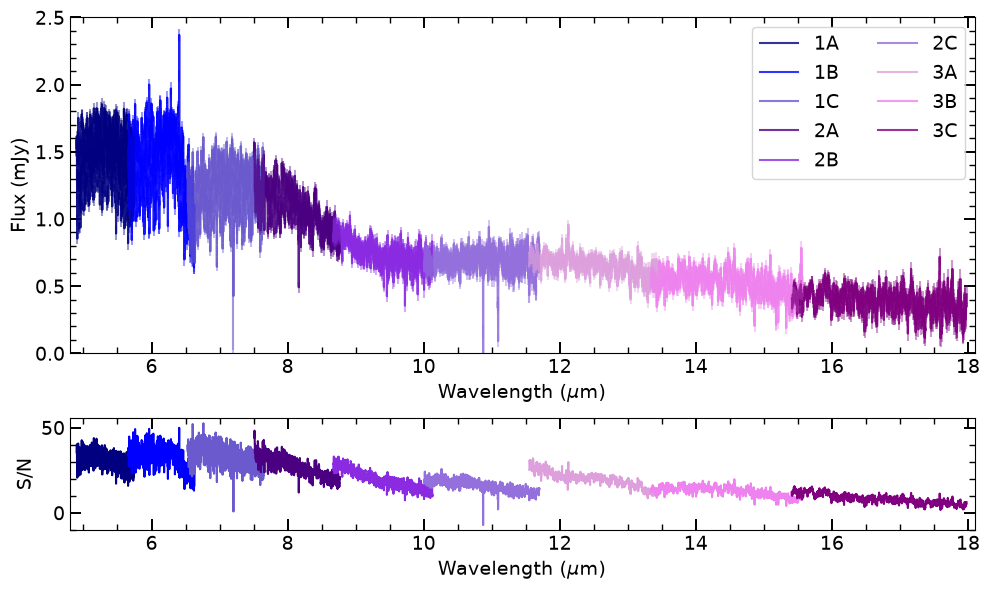

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), gridspec_kw={"height_ratios": [3, 1]}, tight_layout=True)
for band in bands:
    ax[0].errorbar(wave[band], flux[band], yerr=err[band], color=colors[band], alpha=0.4)
    ax[0].plot(wave[band], flux[band], color=colors[band], label=band, alpha=0.8)

    ax[1].plot(wave[band], flux[band] / err[band], color=colors[band], label=f"S/N {band}")

ax[0].set_ylabel("Flux (mJy)", fontsize=fs)
ax[1].set_ylabel("S/N", fontsize=fs)
ax[0].set_xlabel(r"Wavelength ($\mu$m)", fontsize=fs)
ax[1].set_xlabel(r"Wavelength ($\mu$m)", fontsize=fs)
for a in ax:
    a.set_xlim(4.8, 18.1)
ax[0].set_ylim(0, 2.5)
ax[0].legend(fontsize=fs, ncol=2)
for a in ax:
    a.tick_params(axis="both", which="both", direction="in", top=True, right=True)
    a.tick_params(which="major", length=8, width=1.4, labelsize=fs)
    a.tick_params(which="minor", length=4, width=1.0)
    a.minorticks_on()
fig.savefig(os.path.join(output_dir, f"Spectrum_{name_system}_all_bands_mJy.pdf"),
            bbox_inches="tight",pad_inches=0.1,)
plt.show()

### ExoREM molecular templates

In [4]:
temp_model = 1000  # K
Rp = 1.27            # planet radius used to scale the model flux
dstar = 12.7       # distance (pc) used to scale the model flux
res = 3700         # resolving power used to degrade the models

path_molec = "/Users/mmalin/Models_spectra/ExoREM/ExoREM_molec/"
model = f"spectra_YGP_{temp_model}K_logg4.0_met1.00_CO0.50.dat"

# Columns of the ExoREM file; templates start at column 4 (spectral_radiosity)
name_column = [
    "wavenumber", "spectral_flux", "spectral_flux_clear", "spectral_flux_full_cover",
    "spectral_radiosity", "spectral_radiosity_thermal", "spectral_radiosity_cia_rayleigh",
    "spectral_radiosity_CH4", "spectral_radiosity_CO", "spectral_radiosity_CO2",
    "spectral_radiosity_FeH", "spectral_radiosity_H2O", "spectral_radiosity_H2S",
    "spectral_radiosity_HCN", "spectral_radiosity_K", "spectral_radiosity_Na",
    "spectral_radiosity_NH3", "spectral_radiosity_PH3", "spectral_radiosity_TiO",
    "spectral_radiosity_VO",]

# One label per column from index 4 onwards
molec_names = [ "Flux", "Flux thermal", "CIA", "CH$_4$", "CO", "CO$_2$", "FeH", "H$_2$O",
    "H$_2$S", "HCN", "K", "Na", "NH$_3$", "PH$_3$", "TiO", "VO",]
molec_colors = {
    "Flux": "black", "Flux thermal": "black", "CIA": "grey", "CH$_4$": "indigo",
    "CO": "red", "CO$_2$": "deepskyblue", "FeH": "orange", "H$_2$O": "mediumblue",
    "H$_2$S": "gold", "HCN": "darkorange", "K": "teal", "Na": "pink",
    "NH$_3$": "green", "PH$_3$": "magenta", "TiO": "grey", "VO": "darkred",}

# Molecules cross-correlated with the data
molec_ccf = ["Flux", "CH$_4$", "CO", "CO$_2$", "H$_2$O", "H$_2$S", "HCN", "NH$_3$", "PH$_3$"]

wave_molec, flux_molec = {}, {}
for col, m in zip(range(4, len(name_column)), molec_names):
    wave_molec[m], flux_molec[m] = load_spectra_molec(
        os.path.join(path_molec, model), col, Rp, dstar,
        degraded=True, res=res, plot=False, savefig=False,)

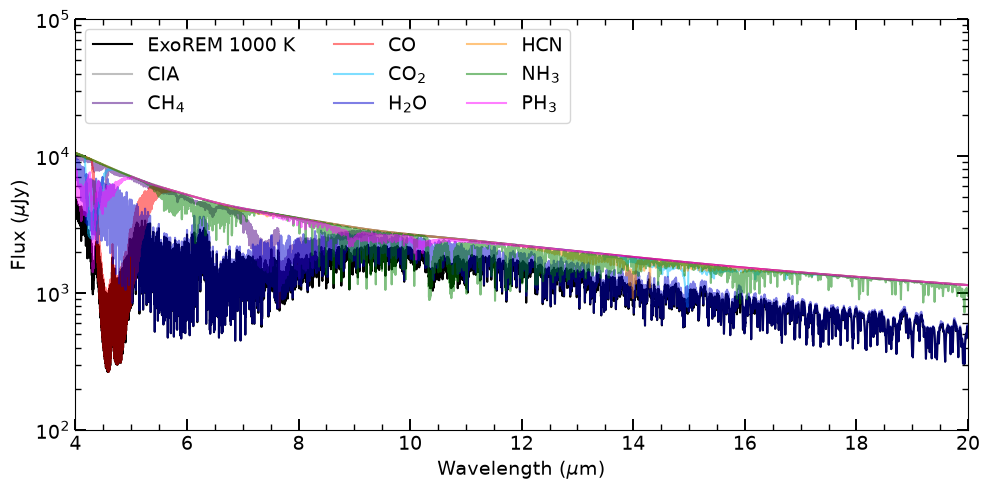

In [5]:
# Plot the model and the molecular contributions
molecules = ["Flux", "CIA", "CH$_4$", "CO", "CO$_2$", "H$_2$O", "HCN", "NH$_3$", "PH$_3$"]

fig, ax = plt.subplots(figsize=(10, 5), tight_layout=True)
for m in molecules:
    if m == "Flux":
        ax.plot(wave_molec[m], flux_molec[m], color=molec_colors[m],  label=f"ExoREM {temp_model} K", zorder=0)
    else:
        ax.plot(wave_molec[m], flux_molec[m], color=molec_colors[m],label=m, alpha=0.5)

    ax.set_xlabel(r"Wavelength ($\mu$m)", fontsize=fs)
    ax.set_ylabel(r"Flux ($\mu$Jy)", fontsize=fs)
    ax.set_yscale("log")
    ax.set_xlim(4, 20)
    ax.set_ylim(1e2, 1e5)
    ax.legend(fontsize=fs, loc="upper left", ncol=3)
    
    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
    ax.tick_params(which="major", length=8, width=1.4, labelsize=fs)
    ax.tick_params(which="minor", length=4, width=1.0)
    ax.minorticks_on()

fig.savefig(os.path.join(output_dir, f"ExoREM_{temp_model}K_model.pdf"), bbox_inches="tight", pad_inches=0.1)
plt.show()

#### CCF for each molecule and band

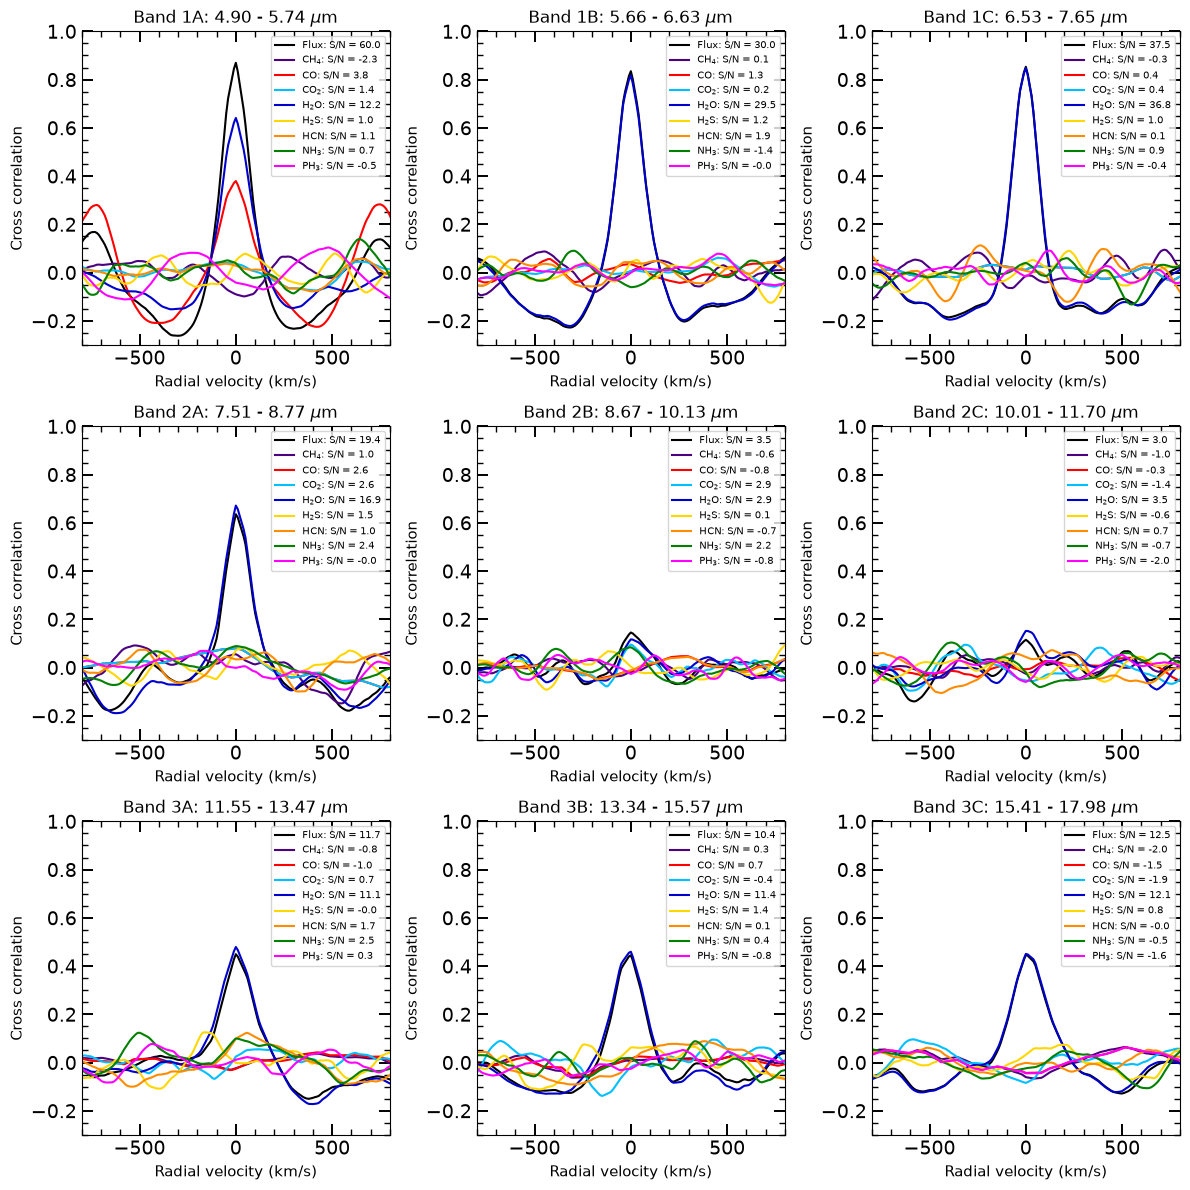

In [6]:
sigma, drv = 10, 10  # gaussian filter parameter, and radial velocity step used to compute the CCF
lim = 1000           # RV range

fig = plt.figure(figsize=(12, 12), tight_layout=True)
for i, band in enumerate(bands):
    if band not in wave:
        continue
    ax = fig.add_subplot(3, 3, i + 1)
    ax.set_title(rf"Band {band}: {np.min(wave[band]):.2f} - {np.max(wave[band]):.2f} $\mu$m")

    # Autocorrelation of the data: same for every molecule, so computed once per band
    rvs_autocorr, ccf_autocorr = compute_ccf_autocorr(wave[band], flux[band], wave[band], sigma=sigma, drv=drv)
    for m in molec_ccf:
        rvs_spectra, ccf_spectra = compute_ccf(wave[band], flux[band], wave_molec[m], flux_molec[m],
                                               sigma=sigma, drv=drv, lim=lim, plot=False)
        rvs_corr, ccf_corr = corr_ccf_from_autocorr(rvs_autocorr, ccf_autocorr, rvs_spectra, ccf_spectra)
        snr_ccf = compute_SN_ccf(rvs_corr, np.array(ccf_corr), 0)[0]
        ax.plot(rvs_spectra, ccf_spectra, color=molec_colors[m], linewidth=1.5,
                label=f"{m}: S/N = {snr_ccf:.1f}")

    ax.set_xlim(-800, 800)
    ax.set_ylim(-0.3, 1)
    ax.set_xlabel("Radial velocity (km/s)", fontsize=11)
    ax.set_ylabel("Cross correlation", fontsize=11)
    ax.legend(fontsize=7, loc="upper right")
    
    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
    ax.tick_params(which="major", length=8, width=1.4, labelsize=fs)
    ax.tick_params(which="minor", length=4, width=1.0)
    ax.minorticks_on()

fig.savefig(os.path.join(output_dir, f"{name_system}_CCF_all_molec_{temp_model}K.pdf"), bbox_inches="tight", pad_inches=0.1,)
plt.show()

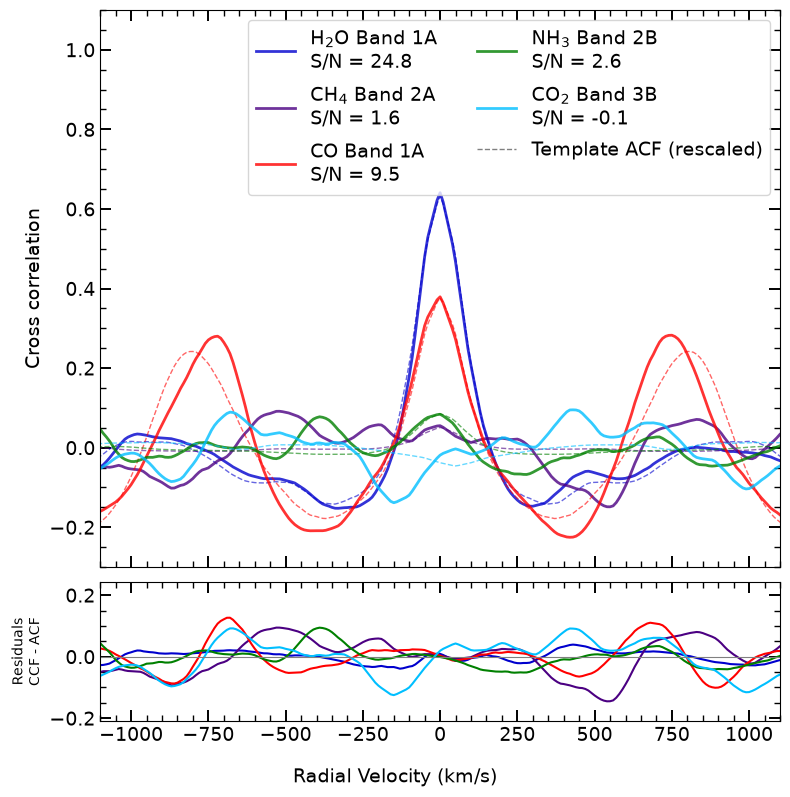

In [7]:
bands_list  = ['1A', '2A', '1A', '2B', '3B']
molec_names = ['H$_2$O', 'CH$_4$', 'CO', 'NH$_3$', 'CO$_2$']
fit_window  = 300     # km/s around the peak used to scale the ACF to the CCF
peak_window = 50      # km/s around 0 to search for the CCF peak
noise_excl  = 200     # km/s around the peak excluded when measuring the noise on the residuals

fig, ax = plt.subplots(2, 1, figsize=(8, 8), sharex=True, tight_layout=True,
                       gridspec_kw={'height_ratios': [4, 1]})

for m, (band, mol_name) in enumerate(zip(bands_list, molec_names)):
    wavelength_model = wave_molec[mol_name]
    flux_model = flux_molec[mol_name]
    color = molec_colors[mol_name]

    # CCF data x template
    rvs_spectra, ccf_spectra = compute_ccf(wave[band], flux[band], wavelength_model, flux_model,
                                           sigma=10, drv=10, lim=1000, plot=False)
    rvs_spectra, ccf_spectra = np.asarray(rvs_spectra), np.asarray(ccf_spectra)

    # S/N
    rvs_autocorr, ccf_autocorr = compute_ccf_autocorr(wave[band], flux[band], wave[band], sigma=10, drv=10)
    rvs_corr, ccf_corr = corr_ccf_from_autocorr(rvs_autocorr, ccf_autocorr, rvs_spectra, ccf_spectra)
    SNR_CCF_auto_corr = compute_SN_ccf(rvs_corr, np.array(ccf_corr), 0)[0]

    # Expected CCF shape: autocorrelation of the template ---
    # template interpolated onto the data grid, then cross-correlated with the template itself,
    # with the same filtering and RV grid as the data CCF
    model_on_data = np.interp(wave[band], wavelength_model, flux_model)
    rvs_acf, acf_model = compute_ccf(wave[band], model_on_data, wavelength_model, flux_model,
                                     sigma=10, drv=10, lim=1000, plot=False)
    rvs_acf, acf_model = np.asarray(rvs_acf), np.asarray(acf_model)

    # shift the ACF to the CCF peak (planet RV)
    near0 = np.abs(rvs_spectra) <= peak_window
    rv_peak = rvs_spectra[near0][np.nanargmax(ccf_spectra[near0])]
    acf_on_grid = np.interp(rvs_spectra, rvs_acf + rv_peak, acf_model, left=np.nan, right=np.nan)

    # scale the ACF to the CCF by least squares around the peak
    win = (np.abs(rvs_spectra - rv_peak) <= fit_window) & np.isfinite(acf_on_grid)
    amp = np.sum(ccf_spectra[win] * acf_on_grid[win]) / np.sum(acf_on_grid[win] ** 2)
    acf_rescaled = amp * acf_on_grid

    residuals = ccf_spectra - acf_rescaled

    # S/N corrected from the autocorrelation
    # signal = CCF at the peak; noise = std of the residuals (CCF - template ACF) in the wings, 
    # so the correlated ACF structure is not counted as noise
    wings = (np.abs(rvs_spectra - rv_peak) > noise_excl) & np.isfinite(residuals)
    noise_res = np.nanstd(residuals[wings])
    i_peak = np.argmin(np.abs(rvs_spectra - rv_peak))
    SNR_acf = ccf_spectra[i_peak] / noise_res

    ax[0].plot(rvs_spectra, ccf_spectra, color=color, alpha=0.8, linewidth=2,
               label=f'{mol_name} Band {band}\nS/N = {SNR_acf:.1f}')
    ax[0].plot(rvs_spectra, acf_rescaled, color=color, alpha=0.6, linewidth=1, linestyle='--')
    ax[1].plot(rvs_spectra, residuals, color=color)

ax[0].plot([], [], color='grey', linestyle='--', linewidth=1, label='Template ACF (rescaled)')
ax[0].set_xlim(-1100, 1100)
ax[0].set_ylim(-0.3, 1.1)
ax[0].set_ylabel("Cross correlation", fontsize=fs)
ax[1].set_ylabel("Residuals\nCCF - ACF", fontsize=fs - 4)
ax[1].axhline(0, color='grey', lw=0.8)
fig.supxlabel("Radial Velocity (km/s)", fontsize=fs)
ax[0].legend(loc=1, ncol=2, fontsize=fs)
for a in ax:
    a.tick_params(axis="both", which="both", direction="in", top=True, right=True)
    a.tick_params(which="major", length=8, width=1.4, labelsize=fs)
    a.tick_params(which="minor", length=4, width=1.0)
    a.minorticks_on()
plt.show()